In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ========================================
# 設定
# ========================================

IMAGE_SIZE = 9
N_CLASS = 3
DATA_DIR = Path("./TrainImage")

# HIDDEN_SIZE = 196
HIDDEN_SIZE = 64

LEARNING_RATE = 0.05
EPOCHS = 10

np.random.seed(0)

# ========================================
# PNG画像の読み込み
# ========================================

X = []
T = []

for class_id in range(N_CLASS):

    class_dir = DATA_DIR / f"class_{class_id}"
    image_files = sorted(class_dir.glob("*.png"))

    for image_file in image_files:

        img = plt.imread(image_file)

        if img.ndim == 3:
            img = img[:, :, 0]

        if img.max() > 1.0:
            img = img / 255.0

        if img.shape != (IMAGE_SIZE, IMAGE_SIZE):
            raise ValueError(
                f"画像サイズが不正です: {image_file}"
            )

        X.append(img)
        T.append(class_id)

X = np.array(X, dtype=float)
T = np.array(T, dtype=int)

T_onehot = np.eye(N_CLASS)[T]

class_counts = np.bincount(T, minlength=N_CLASS)

print("Loaded images:", len(X))
print("Image shape:", X.shape)
print("Class counts:", class_counts)

Loaded images: 300
Image shape: (300, 9, 9)
Class counts: [100 100 100]


In [2]:
# ========================================
# 入力を1次元化
# ========================================

X_flat = X.reshape(len(X), -1)

INPUT_SIZE = IMAGE_SIZE * IMAGE_SIZE

# ========================================
# 重み初期化
# ========================================

W1 = np.random.randn(INPUT_SIZE, HIDDEN_SIZE) * 0.1
b1 = np.zeros(HIDDEN_SIZE)

W2 = np.random.randn(HIDDEN_SIZE, N_CLASS) * 0.1
b2 = np.zeros(N_CLASS)

print()
print("Input size :", INPUT_SIZE)
print("Hidden size:", HIDDEN_SIZE)
print("Output size:", N_CLASS)

n_param = (
    INPUT_SIZE * HIDDEN_SIZE
    + HIDDEN_SIZE
    + HIDDEN_SIZE * N_CLASS
    + N_CLASS
)

print("Total parameters:", n_param)


Input size : 81
Hidden size: 64
Output size: 3
Total parameters: 5443


In [3]:
# ========================================
# 活性化関数
# ========================================

def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -50, 50)))

def softmax(x):
    x = x - np.max(x)
    y = np.exp(x)
    return y / np.sum(y)

# ========================================
# 順伝播
# ========================================

def forward(x, W1, b1, W2, b2):

    z1 = np.dot(x, W1) + b1
    h = sigmoid(z1)

    z2 = np.dot(h, W2) + b2
    y = softmax(z2)

    return h, y

In [4]:
# ========================================
# 学習
# ========================================

def train(X, T_onehot,
          W1, b1,
          W2, b2,
          epochs,
          learning_rate):

    error_history = []
    accuracy_history = []

    for epoch in range(epochs):

        indices = np.random.permutation(len(X))

        total_error = 0
        correct = 0

        for n in indices:

            x = X[n]
            t = T_onehot[n]

            # -----------------
            # forward
            # -----------------

            h, y = forward(x, W1, b1, W2, b2)

            error = 0.5 * np.sum((y - t) ** 2)
            total_error += error

            if np.argmax(y) == np.argmax(t):
                correct += 1

            # -----------------
            # 出力層
            # -----------------

            delta_y = y - t
            delta_out = y * (
                delta_y - np.sum(y * delta_y)
            )

            # -----------------
            # 出力層勾配
            # -----------------

            dW2 = np.outer(h, delta_out)
            db2 = delta_out

            # -----------------
            # 隠れ層誤差
            # -----------------

            delta_h = np.dot(W2, delta_out)
            delta_h *= h * (1.0 - h)

            # -----------------
            # 入力→隠れ層勾配
            # -----------------

            dW1 = np.outer(x, delta_h)
            db1 = delta_h

            # -----------------
            # 更新
            # -----------------

            W2 -= learning_rate * dW2
            b2 -= learning_rate * db2

            W1 -= learning_rate * dW1
            b1 -= learning_rate * db1

        error_history.append(total_error / len(X))
        accuracy_history.append(correct / len(X))

        if (epoch + 1) % 2 == 0:
            print(
                "Epoch:",
                epoch + 1,
                "Error:",
                error_history[-1],
                "Accuracy:",
                accuracy_history[-1]
            )

    return (
        W1, b1,
        W2, b2,
        error_history,
        accuracy_history
    )

# ========================================
# 分類
# ========================================

def predict(X, W1, b1, W2, b2):

    predictions = []

    for x in X:

        h, y = forward(
            x,
            W1, b1,
            W2, b2
        )

        predictions.append(np.argmax(y))

    return np.array(predictions)

# ========================================
# 学習前
# ========================================

pred_before = predict(
    X_flat,
    W1, b1,
    W2, b2
)

accuracy_before = np.mean(
    pred_before == T
)

# ========================================
# 学習
# ========================================

(
    W1, b1,
    W2, b2,
    error_history,
    accuracy_history
) = train(
    X_flat,
    T_onehot,
    W1, b1,
    W2, b2,
    EPOCHS,
    LEARNING_RATE
)

# ========================================
# 学習後
# ========================================

pred_after = predict(
    X_flat,
    W1, b1,
    W2, b2
)

accuracy_after = np.mean(
    pred_after == T
)

print()
print("Accuracy before learning:",
      accuracy_before)

print("Accuracy after learning:",
      accuracy_after)

Epoch: 2 Error: 0.25109787493675767 Accuracy: 0.6766666666666666
Epoch: 4 Error: 0.08825319794390048 Accuracy: 0.9666666666666667
Epoch: 6 Error: 0.042336197315929365 Accuracy: 0.9833333333333333
Epoch: 8 Error: 0.024664618306674147 Accuracy: 0.99
Epoch: 10 Error: 0.017992438037750358 Accuracy: 1.0

Accuracy before learning: 0.38
Accuracy after learning: 1.0


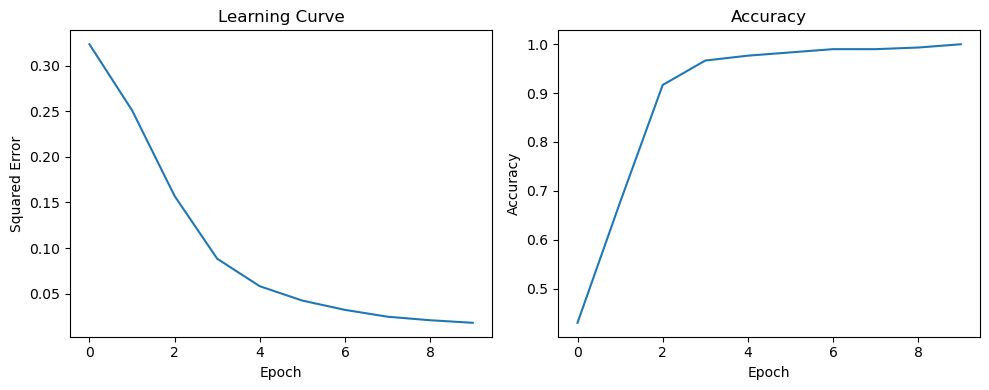

In [5]:
# ========================================
# 学習曲線
# ========================================

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(error_history)
plt.xlabel("Epoch")
plt.ylabel("Squared Error")
plt.title("Learning Curve")

plt.subplot(1, 2, 2)
plt.plot(accuracy_history)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy")

plt.tight_layout()
plt.show()

In [6]:
print("\nCNN parameter =", 631)
print("MLP parameter =", n_param)
print("Ratio =", n_param / 631)


CNN parameter = 631
MLP parameter = 5443
Ratio = 8.625990491283677


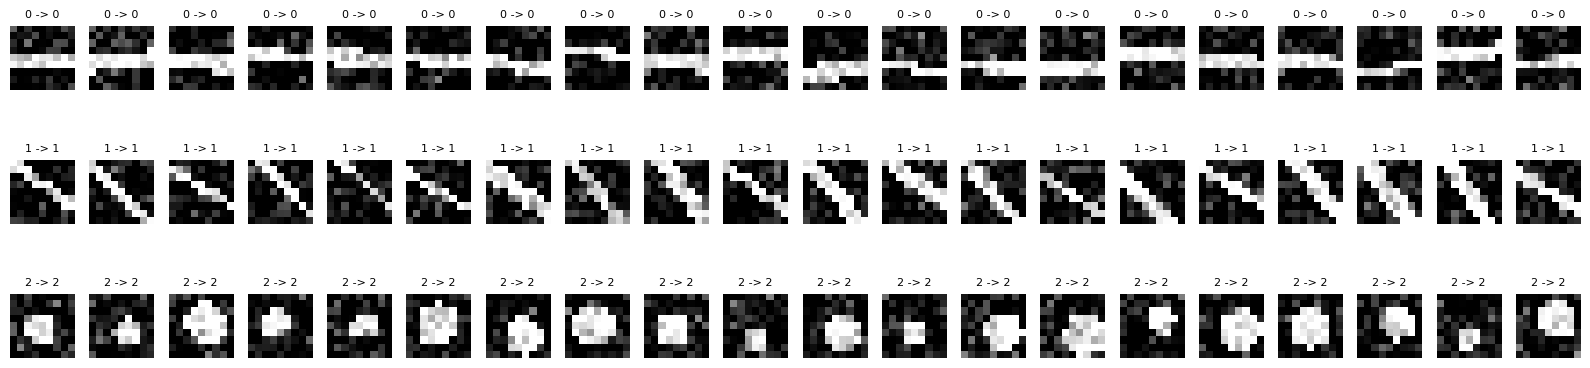

In [7]:
# ========================================
# 入力データと分類結果の表示
# ========================================

MAX_DISPLAY = 20
fig, axes = plt.subplots(N_CLASS, MAX_DISPLAY, figsize=(MAX_DISPLAY * 0.8, N_CLASS * 1.5), squeeze=False)

for class_id in range(N_CLASS):
    indices = np.where(T == class_id)[0]

    for col in range(MAX_DISPLAY):
        ax = axes[class_id, col]

        if col < len(indices):
            n = indices[col]
            ax.imshow(X[n], cmap="gray")
            ax.set_title(str(T[n]) + " -> " + str(pred_after[n]), fontsize=8)

        ax.axis("off")

plt.tight_layout()
plt.show()